In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [79]:
df = pd.read_csv('/content/sample_data/creditcard.csv')

In [80]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [81]:
df.shape

(284807, 31)

In [82]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [83]:
df['Class'].value_counts()

,count
Class,
0,284315
1,492


In [84]:
df['Class'].value_counts(normalize=True)*100

,proportion
Class,
0,99.827251
1,0.172749


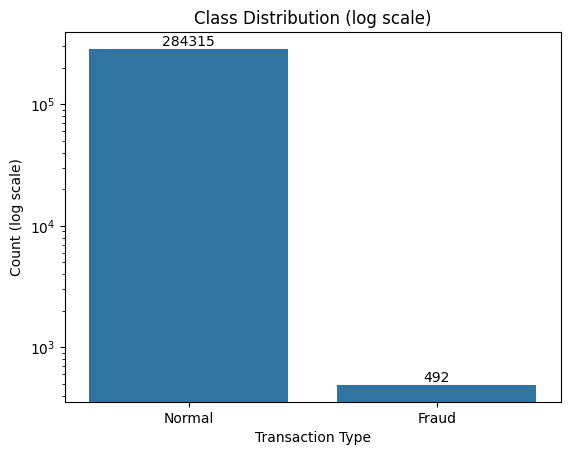

In [85]:
ax = sns.countplot(data= df ,x='Class')
plt.yscale('log')
plt.title('Class Distribution (log scale)')
plt.xlabel('Transaction Type')
plt.ylabel('Count (log scale)')
ax.set_xticklabels(['Normal','Fraud'])
for c in ax.containers:
    ax.bar_label(c)
plt.show()

In [86]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [87]:
df[['Time','Amount']].describe().round(2)

,Time,Amount
count,284807.00,284807.00
mean,94813.86,88.35
std,47488.15,250.12
min,0.00,0.00
25%,54201.50,5.60
50%,84692.00,22.00
75%,139320.50,77.16
max,172792.00,25691.16


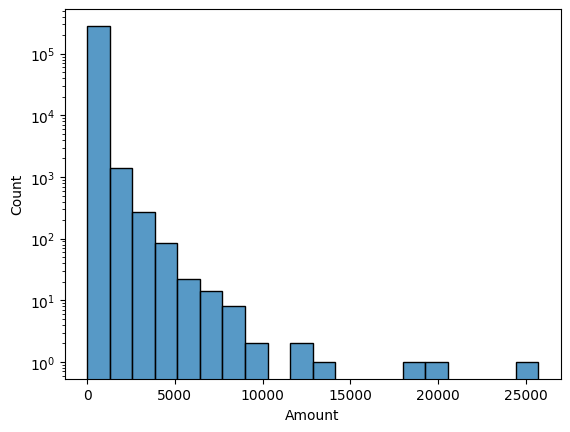

In [88]:
sns.histplot(data= df, x='Amount',bins=20)
plt.yscale('log')

<Axes: >

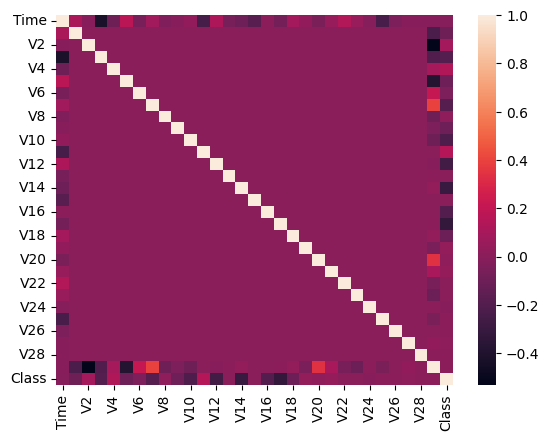

In [89]:
sns.heatmap(df.corr())

In [90]:
x = df.drop('Class',axis=1)
y = df['Class']

In [91]:
x.shape

(284807, 30)

In [92]:
y.shape

(284807,)

In [103]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [99]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(227845, 30)
(56962, 30)
(227845,)
(56962,)


In [100]:
print(y_train.value_counts())
print(y_test.value_counts())

Class
0    227451
1       394
Name: count, dtype: int64
Class
0    56864
1       98
Name: count, dtype: int64


In [104]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [106]:
x_train = x_train.copy()
x_test = x_test.copy()

x_train[['Time', 'Amount']] = scaler.fit_transform(x_train[['Time', 'Amount']])
x_test[['Time', 'Amount']] = scaler.transform(x_test[['Time', 'Amount']])

In [107]:
x_train[['Time','Amount']].describe()

,Time,Amount
count,2.278450e+05,2.278450e+05
mean,-1.407707e-16,-2.020811e-17
std,1.000002e+00,1.000002e+00
min,-1.998073e+00,-3.516894e-01
25%,-8.561495e-01,-3.291944e-01
50%,-2.122647e-01,-2.639429e-01
75%,9.366285e-01,-4.262209e-02
max,1.640549e+00,1.021170e+02


In [108]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(x_train, y_train)

LogisticRegression(max_iter=1000)

In [109]:
from sklearn.metrics import classification_report

y_pred = lr.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



In [120]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [121]:
history= model.fit(
    x_train ,y_train,
    epochs=10,
    batch_size=256,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9730 - loss: 0.0815 - val_accuracy: 0.9992 - val_loss: 0.0051
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9993 - loss: 0.0044 - val_accuracy: 0.9993 - val_loss: 0.0038
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9994 - loss: 0.0034 - val_accuracy: 0.9993 - val_loss: 0.0033
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9994 - loss: 0.0031 - val_accuracy: 0.9994 - val_loss: 0.0034
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9994 - loss: 0.0029 - val_accuracy: 0.9993 - val_loss: 0.0035
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9995 - loss: 0.0027 - val_accuracy: 0.9994 - val_loss: 0.0030
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9994 - loss: 0.0026 - val_accuracy: 0.9994 - val_loss: 0.0030
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9995 - loss: 0.0024 - val_accuracy: 

In [122]:
y_prob = model.predict(x_test)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step


In [123]:
y_pred_ann = (y_prob > 0.5).astype(int)

In [124]:
print(classification_report(y_test, y_pred_ann))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.85      0.76      0.80        98

    accuracy                           1.00     56962
   macro avg       0.93      0.88      0.90     56962
weighted avg       1.00      1.00      1.00     56962



In [125]:
# weight for fraud = normal count / fraud count
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
class_weight = {0: 1, 1: neg / pos}
print(class_weight)

# rebuild a fresh model
model_w = keras.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model_w.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy'])

model_w.fit(x_train, y_train,
            epochs=10,
            batch_size=256,
            validation_split=0.2,
            class_weight=class_weight)

y_pred_w = (model_w.predict(x_test) > 0.5).astype(int)
print(classification_report(y_test, y_pred_w))

{0: 1, 1: np.float64(577.2868020304569)}
Epoch 1/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9752 - loss: 0.5337 - val_accuracy: 0.9796 - val_loss: 0.1438
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9778 - loss: 0.3221 - val_accuracy: 0.9777 - val_loss: 0.1085
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9777 - loss: 0.2612 - val_accuracy: 0.9829 - val_loss: 0.0650
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9777 - loss: 0.2253 - val_accuracy: 0.9644 - val_loss: 0.1224
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9752 - loss: 0.2010 - val_accuracy: 0.9767 - val_loss: 0.0855
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9794 - loss: 0.1735 - val_accuracy: 0.9794 - val_loss: 0.0677
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9772 - loss: 0.1681 - val_accuracy: 0.9857 - val_loss: 0.0536
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy:

In [126]:
model.save('fraud_model.keras')

test = x_test.copy()
test['Class'] = y_test.values
fraud = test[test['Class'] == 1]
normal = test[test['Class'] == 0].sample(2000, random_state=42)
pd.concat([fraud, normal]).to_csv('demo_data.csv', index=False)

from google.colab import files
files.download('fraud_model.keras')
files.download('demo_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>